In [1]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [2]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

In [3]:
### Create function for Cressman Analysis ###
def cressman_analysis(x_ob, y_ob, raw_obs, x_grid, y_grid, roi, target_x=None, target_y=None):

    if target_x is None:
         target_x = x_grid
         target_y = y_grid

    # empty arrs for storing info
    analysis_pts = np.full(target_x.shape, np.nan)
    number_of_obs = np.zeros(target_x.shape)

    for x in range(target_x.shape[0]):
            for y in range(target_x.shape[1]):
                
                # define grid pts and rel distance between grid pt and obs
                x_grid_pt, y_grid_pt = target_x[x, y], target_y[x, y]
                rel_dist = np.sqrt((x_ob - x_grid_pt)**2 + (y_ob - y_grid_pt)**2)

                # save sum of true bools if rel dist is inside roi
                inside_roi_bool = (rel_dist <= roi)  & np.isfinite(raw_obs)
                number_of_obs[x,y] = np.sum(inside_roi_bool) 

                if number_of_obs[x, y] == 0:
                     continue

                # compute cressman weights
                weights = ((roi**2 - rel_dist[inside_roi_bool]**2)/
                           (roi**2 + rel_dist[inside_roi_bool]**2))

                # analysis using weights
                analysis_pts[x, y] = (np.sum(weights * raw_obs[inside_roi_bool]) / np.sum(weights))

    return analysis_pts, number_of_obs

In [4]:
### Create function for bilinear interpolation ###
def bilinear_interp(analysis_pts, x_grid, y_grid, x_point, y_point):

    x = x_grid[:,0]
    y = y_grid[0,:]

    dx = x[1] - x[0]
    dy = y[1] - y[0]

    i = int(np.floor((x_point - x[0]) / dx))
    j = int(np.floor((y_point - y[0]) / dy))

    # see if pt is inside the analysis grid
    if i < 0 or i >= len(x) -1 or j < 0 or j >= len(y) -1:
        return np.nan

    dx_cell = (x_point - x[i])/dx
    dy_cell = (y_point - y[j])/dy

    # get surrounding pts relative to current pt
    pt_00 = analysis_pts[i, j]
    pt_10 = analysis_pts[i+1, j]
    pt_01 = analysis_pts[i, j+1]
    pt_11 = analysis_pts[i+1, j+1]

    interp_term_1 = ((1-dx_cell)*(1-dy_cell) * pt_00)
    interp_term_2 = (dx_cell * (1-dy_cell) * pt_10)
    interp_term_3 = ((1-dx_cell) * dy_cell * pt_01)
    interp_term_4 = (dx_cell * dy_cell * pt_11)

    return interp_term_1 + interp_term_2 + interp_term_3 + interp_term_4

In [5]:
### Read in observations ###
raw_obs = np.loadtxt("RAOBs_201903131200.txt", delimiter=',', dtype=str)
raw_500s = np.array([float(raw_obs[i][3]) for i in range(len(raw_obs))])

In [6]:
### Set up analysis map with a 21x27 rectangular grid of points ###
# params
R = 6371.0
phi_0 = np.deg2rad(60.0)
lambd_0 = np.deg2rad(-100.0)
k_0 = (1+np.sin(phi_0))/2

R_map = R * 100000 / 15000000

rho = 6371000

# grid points 
nx = 21
ny = 27
dx, x_0 = 1.27, 25
dy, y_0 = 1.27, -15.5
x = x_0 + np.arange(nx) * dx
y = y_0 + np.arange(ny) * dy
x_grid, y_grid = np.meshgrid(x, y, indexing='ij')

print(f'x: {x}\ny: {y}\nR_map: {R_map}')

x: [25.   26.27 27.54 28.81 30.08 31.35 32.62 33.89 35.16 36.43 37.7  38.97
 40.24 41.51 42.78 44.05 45.32 46.59 47.86 49.13 50.4 ]
y: [-15.5  -14.23 -12.96 -11.69 -10.42  -9.15  -7.88  -6.61  -5.34  -4.07
  -2.8   -1.53  -0.26   1.01   2.28   3.55   4.82   6.09   7.36   8.63
   9.9   11.17  12.44  13.71  14.98  16.25  17.52]
R_map: 42.473333333333336


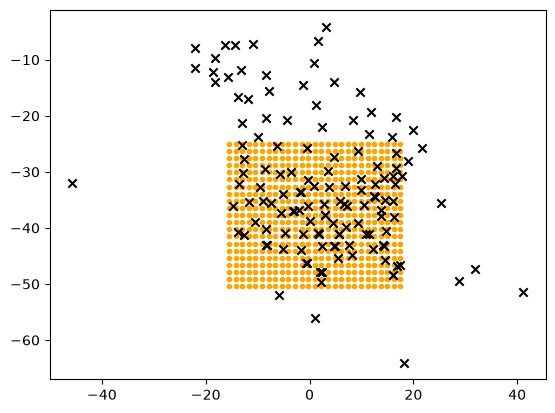

In [7]:
### convert obs lat/long to x,y ###
# open raw lat/lon
raw_lats = [float(raw_obs[i][1]) for i in range(len(raw_obs))]
raw_lons = [float(raw_obs[i][2]) for i in range(len(raw_obs))]

# convert to rad and create lambda
phi = np.deg2rad(raw_lats)
lamdb = np.deg2rad(raw_lons) - lambd_0

# eqn for r: r = rho * sigma * cos(phi).....or..... r= R*(1+sin(phi_0)/1+sin(phi))*cos(phi)
r = R * ((1 + np.sin(phi_0))/(1 + np.sin(phi))) * np.cos(phi) /150 

# convert
x_ob = r * np.cos(lamdb)
y_ob = r * np.sin(lamdb)

# simple test of grid and obs
plt.scatter(y_grid, -x_grid, marker=".", color='orange')
plt.scatter(y_ob, -x_ob, marker='x', color='k')

In [8]:
### Perform 500mb geopotential height analyses using a Cressman weighting Function###
#Use radii of influence 4, 2.5, 1.5 *dmin

pt_distances = []

for i in range(len(x_ob)):
    dist = np.sqrt((x_ob - x_ob[i])**2 + (y_ob - y_ob[i])**2)
    dist[i] = np.inf
    pt_distances.append(np.min(dist))

dmin = np.mean(pt_distances)
roi_1 = 4.0 * dmin
roi_2 = 2.5 * dmin
roi_3 = 1.5 * dmin

print(dmin)
print(roi_1, roi_2, roi_3)

2.554870082007142
10.219480328028569 6.387175205017855 3.8323051230107135


In [9]:
######## PASS 1 ########
# pass 1 analysis field with cressman
analysis_pts_1, number_of_obs_1 = cressman_analysis(x_ob, y_ob, raw_500s, x_grid, y_grid, roi_1)




######## PASS 2 ########
# interp pass1 analysis to the observation locs
analysis_1_interp = np.array([bilinear_interp(analysis_pts_1, x_grid, y_grid, x_ob[k], y_ob[k]) for k in range(len(raw_500s))])

# use cressman again to get values for stations outside interp (nan'ed during biinterp)
missing_vals_bool = ~np.isfinite(analysis_1_interp)
cressman_interp_of_missing_vals, _ = cressman_analysis(x_grid.ravel(), y_grid.ravel(), analysis_pts_1.ravel(), x_grid, y_grid, roi_1,
                                                       target_x=x_ob[missing_vals_bool, None], target_y=y_ob[missing_vals_bool, None])
analysis_1_interp[missing_vals_bool] = cressman_interp_of_missing_vals[:,0]

# pass-1 reiduals at ob locations
analysis_1_resid = raw_500s - analysis_1_interp

# analize pass-1 residuals for pass-2's correction to pass-1
analysis_1_correction, number_of_obs_2 = cressman_analysis(x_ob, y_ob, analysis_1_resid, x_grid, y_grid, roi_2)

# copy analysis-1 and add the corrections to analysis-1 only if the pts arent nan, thus making pass-2 analysis
analysis_pts_2 = analysis_pts_1.copy()
where_analysis_1_pts_are_valid = np.isfinite(analysis_pts_1) & np.isfinite(analysis_1_correction)
analysis_pts_2[where_analysis_1_pts_are_valid] += analysis_1_correction[where_analysis_1_pts_are_valid]



######## PASS 3 ########
# interp pass2 analysis to the observation locs
analysis_2_interp = np.array([bilinear_interp(analysis_pts_2, x_grid, y_grid, x_ob[k], y_ob[k]) for k in range(len(raw_500s))])

# use cressman again to get values for stations outside interp (nan'ed during biinterp)
missing_vals_bool = ~np.isfinite(analysis_2_interp)
cressman_interp_of_missing_vals, _ = cressman_analysis(x_grid.ravel(), y_grid.ravel(), analysis_pts_2.ravel(), x_grid, y_grid, roi_2,
                                                       target_x=x_ob[missing_vals_bool, None], target_y=y_ob[missing_vals_bool, None])
analysis_2_interp[missing_vals_bool] = cressman_interp_of_missing_vals[:,0]

# pass-2 reiduals at ob locations
analysis_2_resid = raw_500s - analysis_2_interp

# analize pass-2 residuals for pass-3's correction to pass-2
analysis_2_correction, number_of_obs_3 = cressman_analysis(x_ob, y_ob, analysis_2_resid, x_grid, y_grid, roi_3)

# copy analysis-2 and add the corrections to analysis-2 only if the pts arent nan, thus making pass-3 analysis
analysis_pts_3 = analysis_pts_2.copy()
where_analysis_2_pts_are_valid = np.isfinite(analysis_pts_2) & np.isfinite(analysis_2_correction)
analysis_pts_3[where_analysis_2_pts_are_valid] += analysis_2_correction[where_analysis_2_pts_are_valid]



# analysis 3 interp for rmse calc
analysis_3_interp = np.array([bilinear_interp(analysis_pts_3, x_grid, y_grid, x_ob[k], y_ob[k]) for k in range(len(raw_500s))])
missing_vals_bool = ~np.isfinite(analysis_3_interp)
cressman_interp_of_missing_vals, _ = cressman_analysis(x_grid.ravel(), y_grid.ravel(), analysis_pts_3.ravel(), x_grid, y_grid, roi_3,
                                                       target_x=x_ob[missing_vals_bool, None], target_y=y_ob[missing_vals_bool, None])
analysis_3_interp[missing_vals_bool] = cressman_interp_of_missing_vals[:,0]




# now a stupid way to get the number of obs used in each roi
_, number_of_obs_1 = cressman_analysis(x_ob, y_ob, raw_500s, x_grid, y_grid, roi_1)
_, number_of_obs_1 = cressman_analysis(x_ob, y_ob, raw_500s, x_grid, y_grid, roi_2)
_, number_of_obs_1 = cressman_analysis(x_ob, y_ob, raw_500s, x_grid, y_grid, roi_3)

In [10]:
### Calculate Analysis Differences
analysis_diff_21 = analysis_pts_2 - analysis_pts_1
analysis_diff_31 = analysis_pts_3 - analysis_pts_1
analysis_diff_32 = analysis_pts_3 - analysis_pts_2


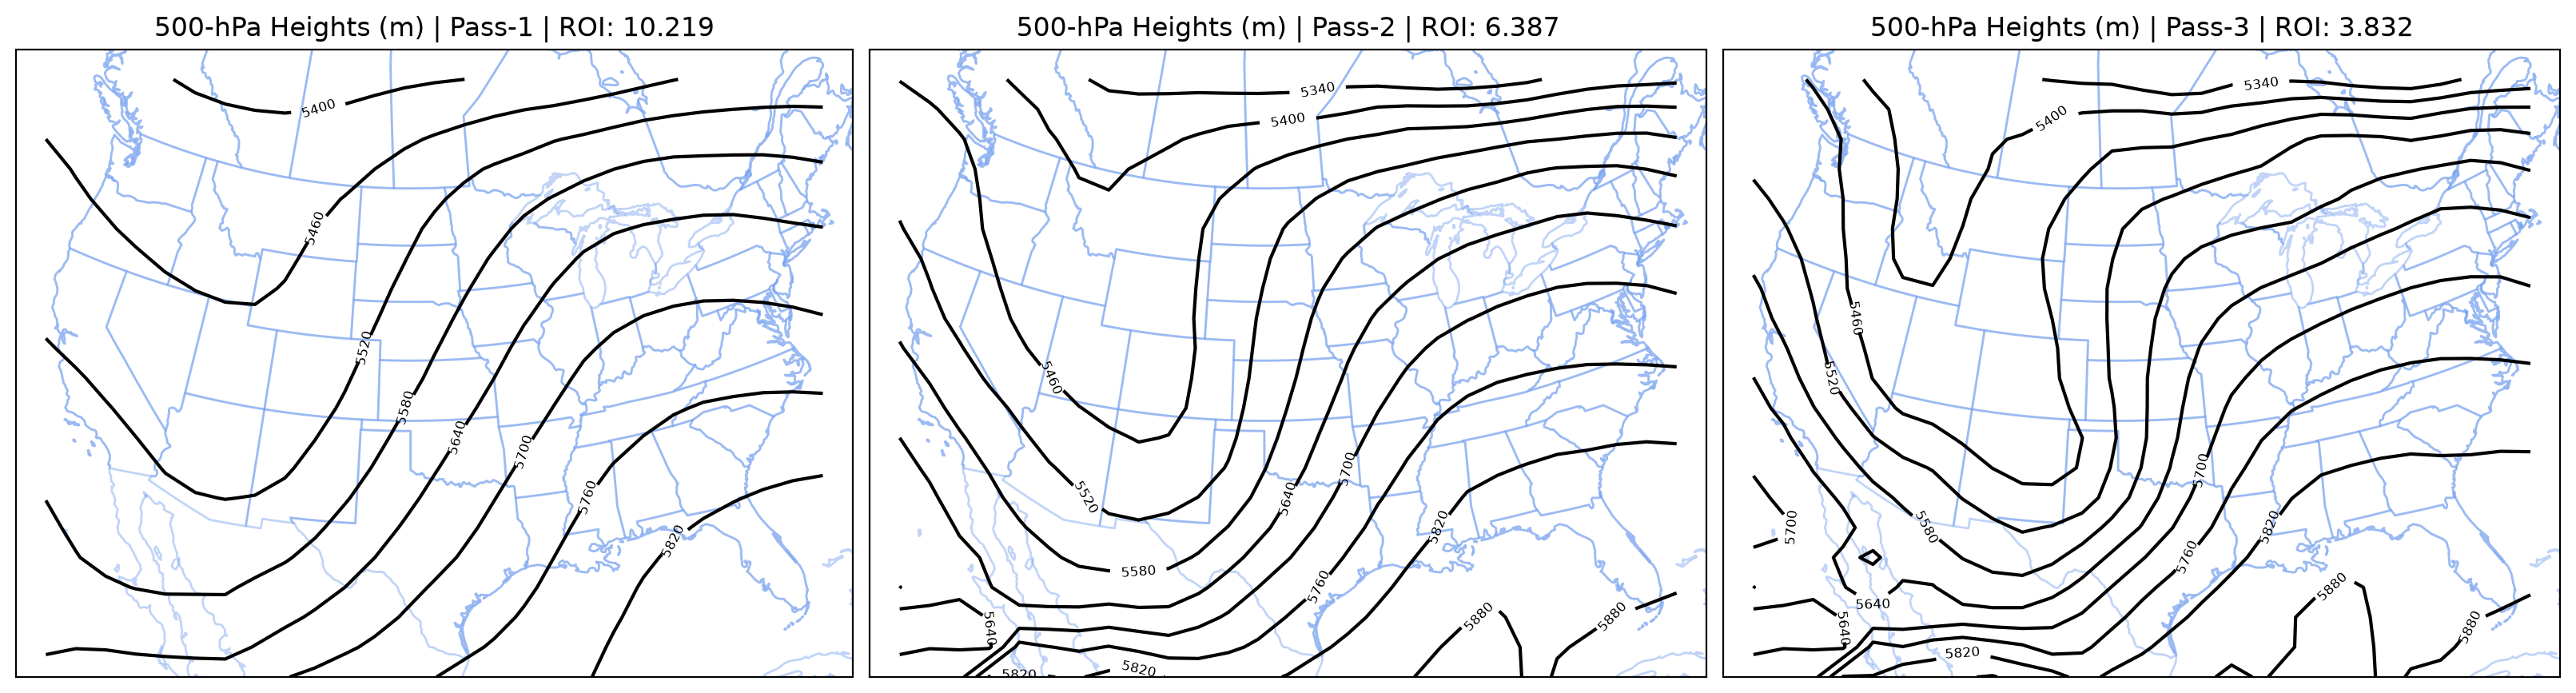

In [11]:
### Plot 500mb analyses over a map ###
#use old code...

r = np.sqrt(x_grid**2 + y_grid**2)
phi = (np.pi/2 - 2*np.arctan(r/(R_map * (1 +np.sin(phi_0)))))
lambd = np.arctan2(y_grid, x_grid)
lon = np.rad2deg(lambd_0 + lambd)
lat = np.rad2deg(phi)


globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=-100, central_latitude=90, true_scale_latitude=60, globe=globe)

fig, axes = plt.subplots(1,3, figsize=(16,8), dpi=200, subplot_kw={'projection':proj}, constrained_layout=True)

#fig = plt.figure(figsize=(8,8),dpi=200)
#ax1 = fig.add_subplot(111,projection=proj)

analysis_data = [analysis_pts_1, analysis_pts_2, analysis_pts_3]
rois = [f"Pass-1 | ROI: {np.round(roi_1,3)}", f"Pass-2 | ROI: {np.round(roi_2,3)}", f"Pass-3 | ROI: {np.round(roi_3,3)}"]

for i in range(0,3):
    axes[i].add_feature(cfeature.STATES, edgecolor='cornflowerblue', alpha=0.4)
    axes[i].add_feature(cfeature.COASTLINE, edgecolor='cornflowerblue', alpha=0.4)
    cs1 = axes[i].contour(lon,lat,analysis_data[i],colors='k', levels=np.arange(0,8000,60),transform=ccrs.PlateCarree())
    plt.clabel(cs1,levels=np.arange(0,8000,60), fontsize=6)
    axes[i].set_title(f"500-hPa Heights (m) | {rois[i]}")
    axes[i].set_box_aspect(0.75)
    
plt.show()

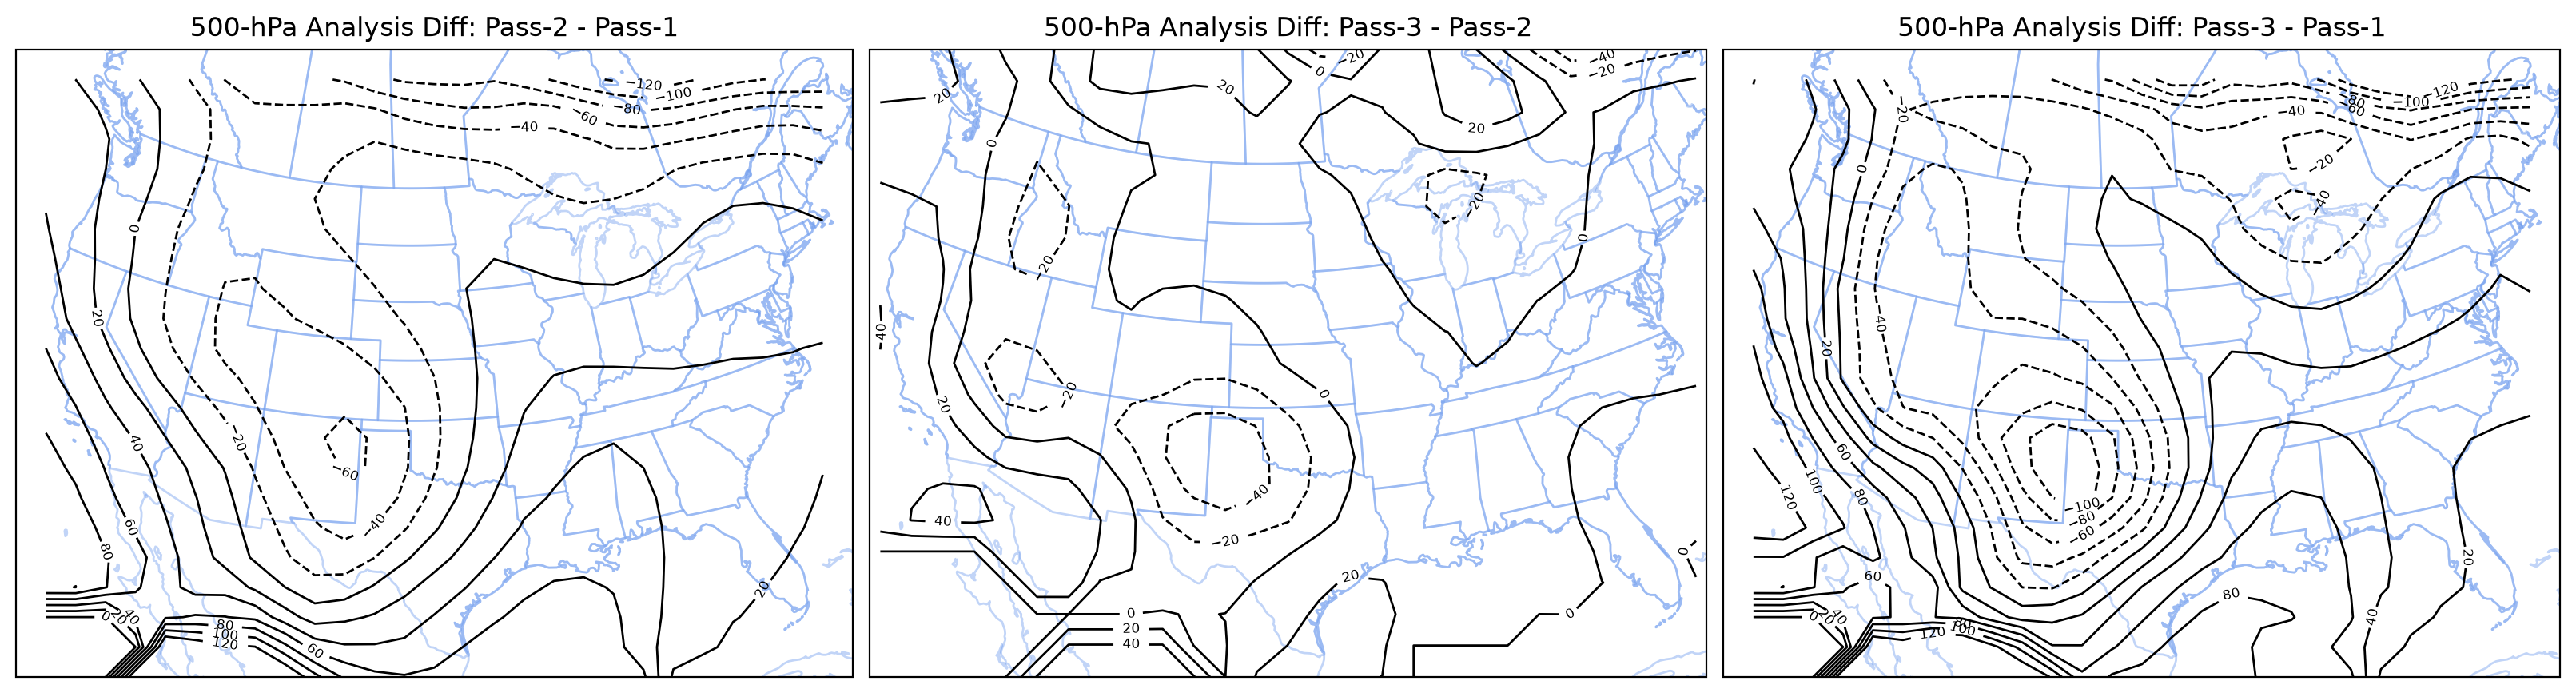

In [12]:
### Plot Analysis Differences ###
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=-100, central_latitude=90, true_scale_latitude=60, globe=globe)

fig, axes = plt.subplots(1,3, figsize=(16,6), dpi=200, subplot_kw={'projection':proj}, constrained_layout=True)

#fig = plt.figure(figsize=(8,8),dpi=200)
#ax1 = fig.add_subplot(111,projection=proj)

analysis_data = [analysis_diff_21, analysis_diff_32, analysis_diff_31]
rois = ["Pass-2 - Pass-1", "Pass-3 - Pass-2", "Pass-3 - Pass-1"]

for i in range(0,3):
    axes[i].add_feature(cfeature.STATES, edgecolor='cornflowerblue', alpha=0.4)
    axes[i].add_feature(cfeature.COASTLINE, edgecolor='cornflowerblue', alpha=0.4)
    cs1 = axes[i].contour(lon,lat,analysis_data[i], colors='k', levels=np.arange(-120, 121, 20), transform=ccrs.PlateCarree(), linewidths=1)
    plt.clabel(cs1,levels=np.arange(-120, 121, 20), fontsize=6)
    axes[i].set_title(f"500-hPa Analysis Diff: {rois[i]}")
    axes[i].set_box_aspect(0.75)

plt.show()

In [13]:
### Store the analyses in text files ##

# NOTE: writing obs, analysis, x/y, etc together in the same file. One file for roi=10 and one for roi=20

def write_file(fn, analysis_pts, number_of_obs):
    with open(fn, "w") as f:

        f.write("x, y, x_cm, y_cm, lat, lon, analysis, number_of_obs\n")

        for x in range(x_grid.shape[0]):
            for y in range(x_grid.shape[1]):
                f.write(f"{int(x)}, " f"{int(y)}, "
                        f"{np.round(x_grid[x,y], 5)}, " f"{np.round(y_grid[x,y], 5)}, "
                        f"{np.round(lat[x,y], 5)}, " f"{np.round(lon[x,y], 5)}, "
                        f"{np.round(analysis_pts[x,y], 5)}, " f"{int(number_of_obs[x,y])}, \n")

write_file("analysis_pass1.txt", analysis_pts_1, number_of_obs_1)
write_file("analysis_pass2.txt", analysis_pts_2, number_of_obs_2)
write_file("analysis_pass3.txt", analysis_pts_3, number_of_obs_3)

In [14]:
### Store the difference fields in text files ###

def write_difference_file(fn, difference):
    with open(fn, "w") as f:

        f.write("x, y, x_cm, y_cm, lat, lon, diff\n")

        for x in range(x_grid.shape[0]):
            for y in range(x_grid.shape[1]):
                f.write(
                    f"{x}, {y}, "
                    f"{np.round(x_grid[x, y], 5)}, "
                    f"{np.round(y_grid[x, y], 5)}, "
                    f"{np.round(lat[x, y], 5)}, "
                    f"{np.round(lon[x, y], 5)}, "
                    f"{np.round(difference[x, y], 5)}\n")

write_difference_file("difference_pass2_minus_pass1.txt", analysis_diff_21)
write_difference_file("difference_pass3_minus_pass1.txt", analysis_diff_31)
write_difference_file("difference_pass3_minus_pass2.txt", analysis_diff_32)

In [15]:
### Store RMS values in text file ###
def compute_rmse(observed, analysis):

    valid_mask = np.isfinite(observed) & np.isfinite(analysis)
    K = np.sum(valid_mask) #len(observed)
    rmse = np.sqrt((np.sum((observed[valid_mask] - analysis[valid_mask])**2)) / (K))

    return rmse 


rmse_1 = compute_rmse(raw_500s, analysis_1_interp)
rmse_2 = compute_rmse(raw_500s, analysis_2_interp)
rmse_3 = compute_rmse(raw_500s, analysis_3_interp)

print(f"RMSE\nPass-1: {rmse_1}\nPass-2: {rmse_2}\nPass-3: {rmse_3}")

with open("rmse_values.txt", "w") as f:
    f.write("pass,rmse_m,\n")
    f.write(f"1,{np.round(rmse_1,5)}\n")
    f.write(f"2,{np.round(rmse_2,5)}\n")
    f.write(f"3,{np.round(rmse_3,5)}")


RMSE
Pass-1: 85.35084349383487
Pass-2: 37.95754682302219
Pass-3: 11.569333186758799


In [ ]:
### In a separte text file (or below), answer the following questions ###
'''

########################################################################################
1 - Describe the general features that you see in your contoured analyses.
    -----------------------------------------------------------------------------------
    Much like the pattern from our pervious homework, the first analysis pass features a
    general western trough-eastern ridge pattern. The trough extends southward from the
    CONUS northern Rockies towards northern Mexico, with a primarily neutral tilt. With
    each pass, the pattern becomes better defined, and the trough takes on varying geometery.
    By pass 2, the trough features what may be an embedded shortwave presenting a more
    negative tilt. This feature is further refined by pass 3 across the Four Corners into
    west Texas. 


########################################################################################
2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    ------------------------------------------------------------------------------------
    Each pass, as expected, reveals smaller scale features and more nuanced trough geometery,
    especially across the Rockies, Great Basin, Southwest, and western Mexico. Pass one is thus 
    the smoothest analysis given a larger ROI without correction toward the observations. 
    Subsequent passes are less smooth because fewer points are used to influence a given
    point's value. It is likely that on pass three, with the smallest ROI in a region with
    few nearby observations, that the closed contour over the Gulf of California is in fact
    a single station and may be erroneous.
    

########################################################################################
3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?
    ------------------------------------------------------------------------------------
    Increasing the number of passes brings out more detail and reduces analysis error (i.e.,
    the analysis is closer to the observations). Less error is generally desirable but the
    tradeoff, especially on the synoptic scale, may be that smaller features become resolved
    by the analysis. Those features may or may not actually exists (i.e. station errors) thus
    the analysis may become too influenced by a single station's observation.

'''